# Exploratory Data Analysis

In this notebook, you will reproduce the exploratory analysis yourself.

For each code cell, read the instructions in the comments and write the required code underneath them. After making each plot or calculation, answer the accompanying questions in the markdown cells.

In [12]:
# TODO:
# Import pandas, numpy, seaborn, and matplotlib.pyplot.
# Use the usual aliases: pd, np, sns, and plt.

# YOUR CODE HERE
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# TODO:
# 1. Load "housing_cleaned.csv" into a DataFrame called housing.
# 2. Display a random sample of 5 rows so you can remind yourself what the data looks like.

# YOUR CODE HERE
housing = pd.read_csv("housing_cleaned.csv")
housing.sample(5)



,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
16682,-121.87,37.31,6.0,3797.0,984.0,2437.0,904.0,36802.0,152400.0,<1H OCEAN
5024,-118.28,33.93,21.0,847.0,278.0,1283.0,277.0,14329.0,94100.0,<1H OCEAN
1216,-120.34,38.25,17.0,5497.0,1056.0,997.0,408.0,29821.0,111500.0,INLAND
1287,-121.83,37.99,23.0,1150.0,174.0,572.0,174.0,49167.0,152400.0,INLAND
14975,-122.42,37.75,52.0,2708.0,762.0,1460.0,741.0,29052.0,400000.0,NEAR BAY


## 1. Latitude and Longitude

Let us start by investigating the geographic variables.

We want to see where the observations are located before bringing house price into the picture.

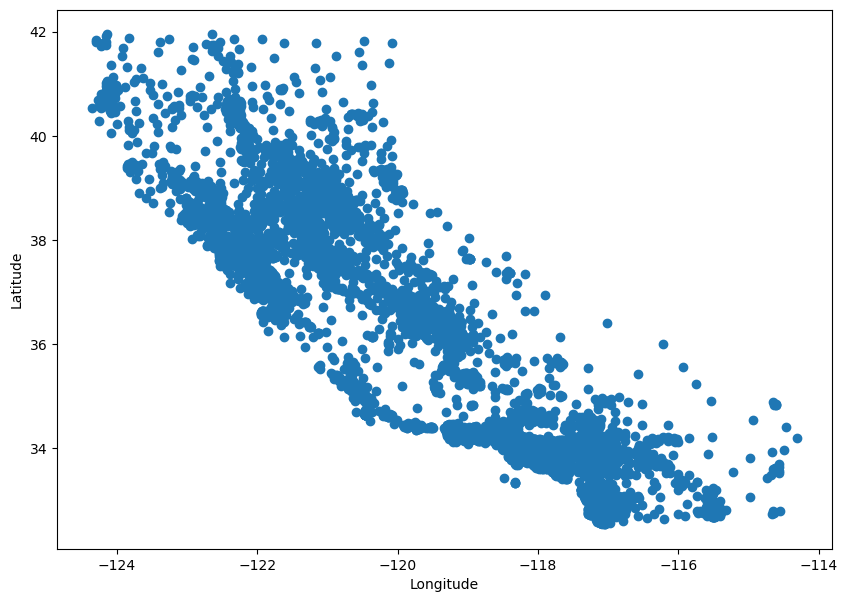

In [3]:
# TODO:
# Make a scatterplot with longitude on the x-axis and latitude on the y-axis.
# Give the axes clear labels and display the plot.
# Use a reasonably large figure so the geographic shape is easy to see.

# YOUR CODE HERE
plt.figure(figsize=(10, 7))

plt.scatter(housing["longitude"], housing["latitude"])

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


### What do you notice?

Look at the shape formed by the points.

- What does the plot look like geographically?
- Does the plot help you understand what latitude and longitude are telling us together?

Write 1–2 sentences here:

**Your observation:**  


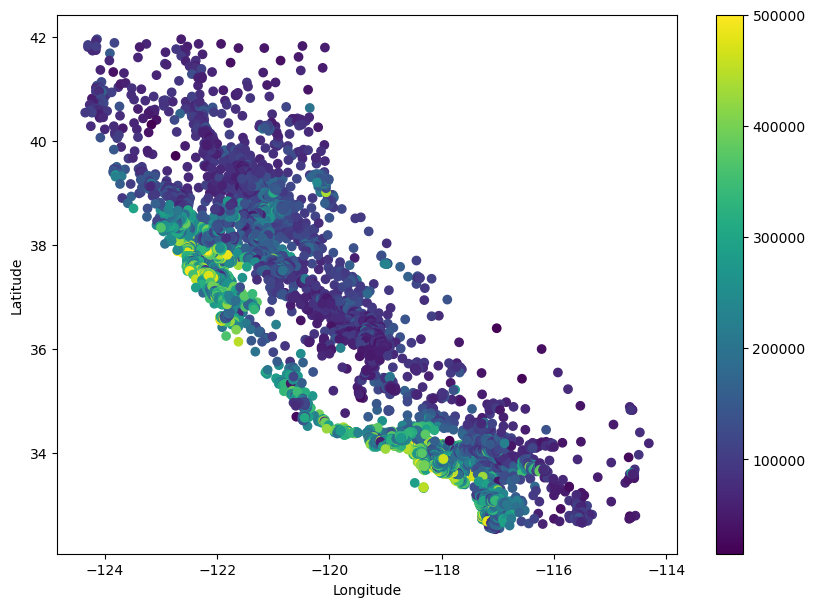

In [4]:
# TODO:
# Make the latitude/longitude scatterplot again.
# This time, color each point according to median_house_value.
# Add a colorbar so we can interpret what the colors mean.
# Label the axes and display the plot.

# YOUR CODE HERE
plt.figure(figsize=(10, 7))

plt.scatter(
    housing["longitude"],
    housing["latitude"],
    c=housing["median_house_value"]
)

plt.colorbar()
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()



### House price and geography

Study the colored map carefully.

- Do expensive and inexpensive areas appear randomly distributed?
- Can you identify regions where house values tend to be higher?
- What does this suggest about whether location may be useful for predicting house price?

**Your observation:**  


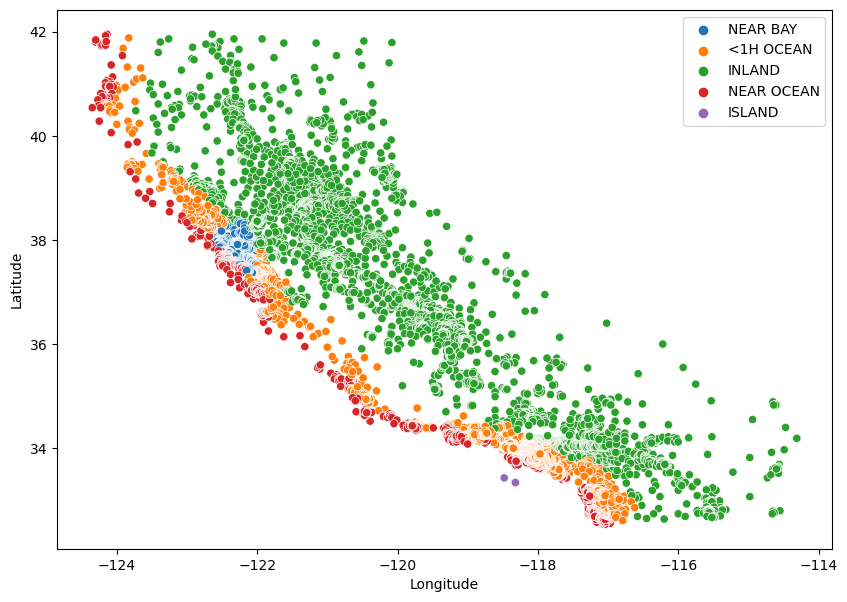

In [5]:
# TODO:
# Make another longitude/latitude scatterplot.
# This time, separate the observations according to ocean_proximity.
#
# One way to do this is:
# - find the unique values of ocean_proximity,
# - loop over those categories,
# - select the rows belonging to each category,
# - plot each category separately and give it a label.
#
# Add axis labels and a legend.

# YOUR CODE HERE

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=housing,
    x="longitude",
    y="latitude",
    hue="ocean_proximity"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()


### Ocean proximity and geography

- Where do the different `ocean_proximity` categories occur?
- Do the category names seem consistent with the geographic locations?
- Which categories occupy noticeably different regions?

**Your observation:**  


## 2. Numerical Variables

Next, let us look at the numerical columns and how they are related to one another.

In [6]:
# TODO:
# Display all column names in the housing DataFrame.
# Decide which columns are numerical and will be useful for the correlation analysis below.

# YOUR CODE HERE
housing.columns
housing.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19475 entries, 0 to 19474
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           19475 non-null  float64
 1   latitude            19475 non-null  float64
 2   housing_median_age  19475 non-null  float64
 3   total_rooms         19475 non-null  float64
 4   total_bedrooms      19475 non-null  float64
 5   population          19475 non-null  float64
 6   households          19475 non-null  float64
 7   median_income       19475 non-null  float64
 8   median_house_value  19475 non-null  float64
 9   ocean_proximity     19475 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.5+ MB


In [7]:
# TODO:
# Create a list called num_col containing the numerical variables that we want to investigate.
#
# Include the numerical housing characteristics and the target variable median_house_value.
# Do not include longitude and latitude in this particular list.

# YOUR CODE HERE

num_col = [
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income",
    "median_house_value"
]



### Correlation

We will look at how correlated the numerical columns are.

Recall:

1. \(-1 \leq \mathrm{corr} \leq 1\).
2. Correlation near \(1\) means two variables tend to increase together.
3. Correlation near \(0\) means there is little linear relationship.
4. Correlation near \(-1\) means one variable tends to decrease as the other increases.


In [8]:
# TODO:
# Using only the columns in num_col, compute the correlation matrix.

# YOUR CODE HERE
housing[num_col].corr() ## --> Calculate the correlation


,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
housing_median_age,1.000000,-0.371274,-0.327308,-0.294553,-0.309135,-0.194259,0.068595
total_rooms,-0.371274,1.000000,0.934147,0.859717,0.921620,0.223865,0.142188
total_bedrooms,-0.327308,0.934147,1.000000,0.879176,0.979144,0.021903,0.074672
population,-0.294553,0.859717,0.879176,1.000000,0.908940,0.042522,0.011153
households,-0.309135,0.921620,0.979144,0.908940,1.000000,0.046430,0.093890
median_income,-0.194259,0.223865,0.021903,0.042522,0.046430,1.000000,0.642733
median_house_value,0.068595,0.142188,0.074672,0.011153,0.093890,0.642733,1.000000


### Read the correlation matrix

Focus on two questions:

1. Which variables have the strongest correlation with `median_house_value`?
2. Which predictor variables are highly correlated with each other?

Why might the second point matter when we later fit a linear regression model?

**Your observation:**  


/Users/im-youngchan/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


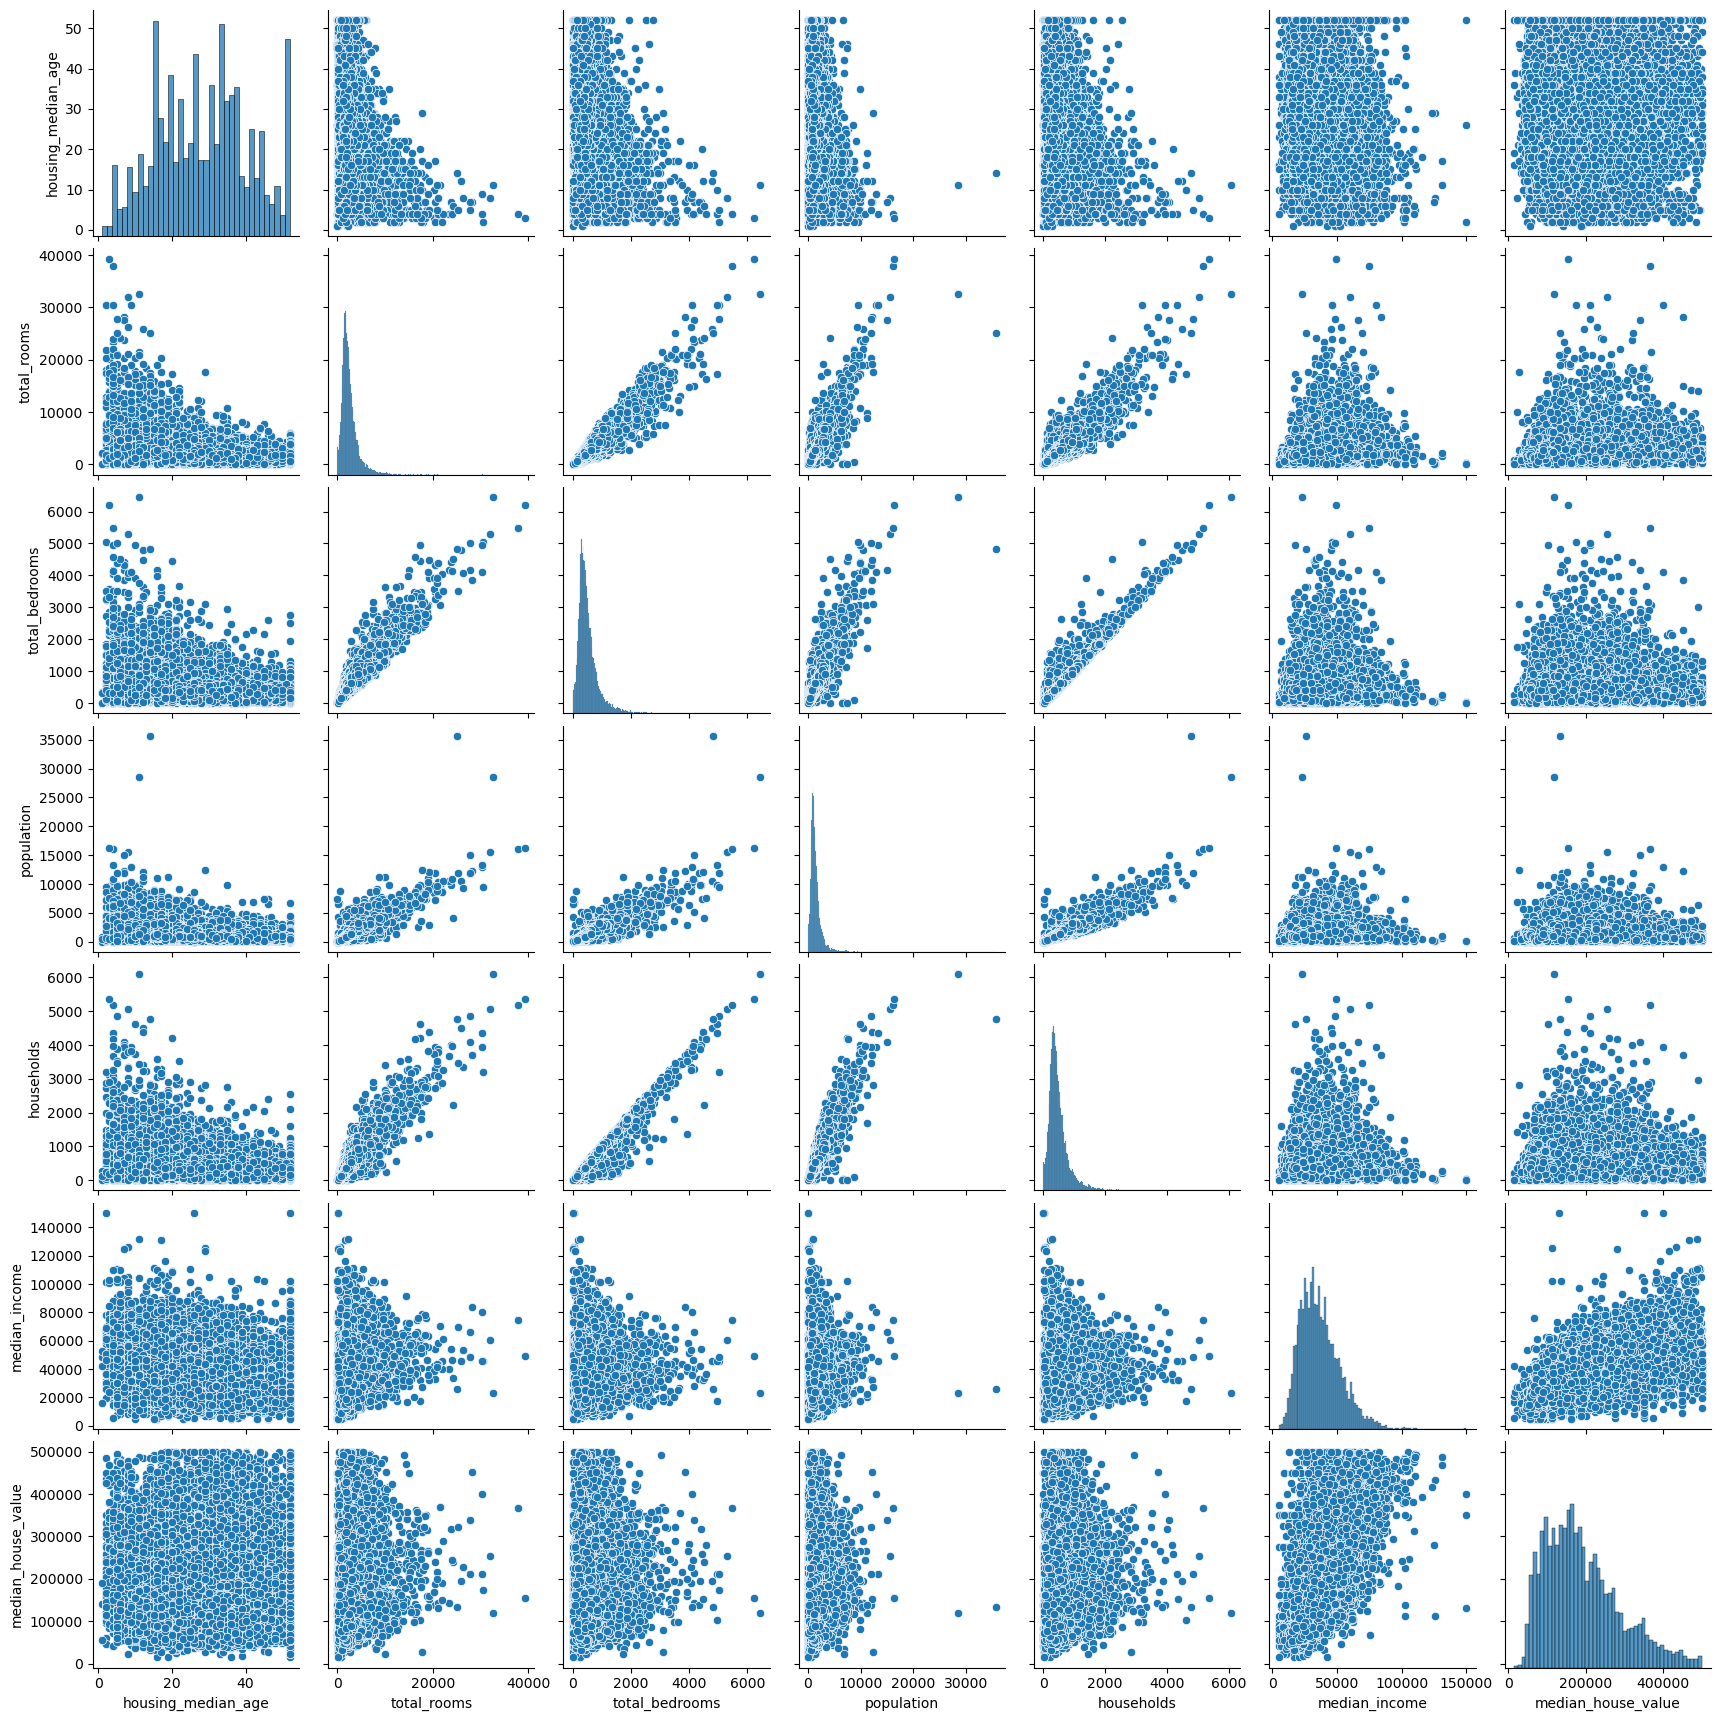

In [9]:
# TODO:
# Make a seaborn pairplot using the numerical columns in num_col.
# Use it to inspect the pairwise relationships and distributions visually.

# YOUR CODE HERE

sns.pairplot(housing[num_col])
plt.show()


### Pairplot observations

Use the pairplot to check whether the correlation matrix is hiding anything interesting.

- Which relationships look approximately linear?
- Which variables are strongly right-skewed?
- Do you see any caps, unusual values, or other patterns worth remembering for later modelling?

**Your observation:**  


## 3. The Categorical Variable: `ocean_proximity`

Finally, let us compare house prices across the different ocean-proximity categories.

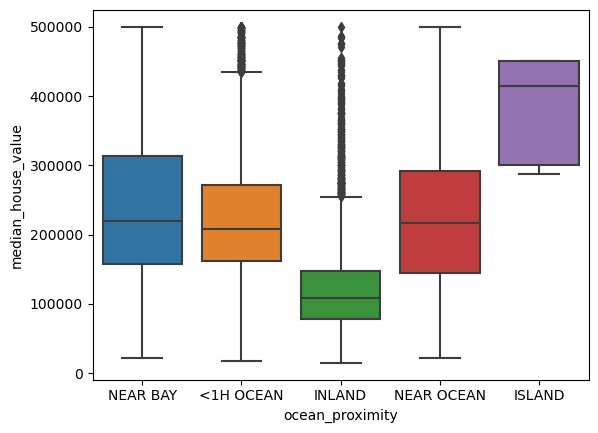

In [11]:
# TODO:
# Make a boxplot with ocean_proximity on the x-axis
# and median_house_value on the y-axis.

# YOUR CODE HERE

sns.boxplot(
    data=housing,
    x="ocean_proximity",
    y="median_house_value"
)

plt.show()


### Compare the categories

Use the boxplot to answer:

- Which category or categories tend to have lower house values?
- Which categories look fairly similar?
- Are any categories unusual?
- Does `ocean_proximity` appear potentially useful for predicting house price?

**Your observation:**  


## EDA Checkpoint

Write down the main conclusions you would carry forward into the modelling stage.

Try to give **3–5 concrete observations or hypotheses** suggested by the analysis above. These should be statements that could influence later feature engineering or model choice.

1.  
2.  
3.  
4.  
5.  
